In [147]:
!pip install pdfplumber pandas

In [59]:
import pdfplumber
import glob
import os
pdf_directory = "Act On Mass/HJRollCalls"  
pdf_files = glob.glob(os.path.join(pdf_directory, "*.pdf"))
for pdf_path in pdf_files:
 with pdfplumber.open(pdf_path) as pdf:
        #Access pages and extract data
       for page in pdf.pages:
            text = page.extract_text()

In [57]:
#Debug + robust parser runner
import os
from pathlib import Path
import glob
import pdfplumber
import pandas as pd
import re

expected_dir = Path("Act On Mass/HJRollCalls")   
out_csv = "rollcalls_all_years.csv"


def clean_name(name):
    return name.replace('*', '').strip()

def parse_pdf_file(pdf_path):
    records = []
    try:
        with pdfplumber.open(pdf_path) as pdf:
            for page in pdf.pages:
                text = page.extract_text()
                if not text:
                    continue
                lines = text.splitlines()
                bill_no = None
                amendment_no = None
                amendment_lines = []

                for line in lines:
                    if not bill_no:
                        m = re.search(r'(H\.\s*\d+)', line)
                        if m:
                            bill_no = m.group(1)
                    if not amendment_no:
                        a = re.search(r'amendment\s*(#\d+)', line, re.IGNORECASE)
                        if a:
                            amendment_no = a.group(1)

                    if re.match(r'^(Yea and Nay|No\.|MASSACHUSETTS|^\s*$)', line):
                        continue

                    if re.search(r'\b(Y|N|X|P)\b', line):
                        amendment_lines.append(line)

                tokens = []
                for l in amendment_lines:
                    tokens.extend(l.strip().split())

                i = 0
                while i < len(tokens):
                    token = tokens[i]
                    if token in ["Y","N","X","P"]:
                        vote = token
                        i += 1
                        name_tokens = []
                        while i < len(tokens) and tokens[i] not in ["Y","N","X","P"]:
                            name_tokens.append(tokens[i]); i += 1
                        name = clean_name(" ".join(name_tokens))
                        if name:
                            records.append({
                                "File": os.path.basename(pdf_path),
                                "Bill No.": bill_no,
                                "Amendment No.": amendment_no,
                                "Legislator Name": name,
                                "Vote": vote
                            })
                    else:
                        i += 1
    except Exception as e:
        print(f"Error parsing {pdf_path}: {e}")
    return records
#working directory
print("Current working directory:", Path.cwd())
#check expected folder
if expected_dir.exists() and expected_dir.is_dir():
    print(f"Found expected directory: {expected_dir.resolve()}")
else:
    print(f"Expected directory not found at: {expected_dir.resolve()}")
    # search for any HJRollCalls folders in tree
    found_dirs = list(Path('.').rglob('HJRollCalls'))
    if found_dirs:
        print("Other HJRollCalls directories found (first 10):")
        for d in found_dirs[:10]:
            print(" -", d.resolve())
        # set the first found to expected_dir for parsing
        expected_dir = found_dirs[0]
        print(f"Will use: {expected_dir.resolve()}")
    else:
        print("No HJRollCalls directory found. I'll search for any PDFs in the project tree...")

# collect pdfs
pdf_paths = list(Path(expected_dir).rglob("*.pdf")) if expected_dir.exists() else list(Path('.').rglob("*.pdf"))

print(f"Total PDF files found: {len(pdf_paths)}")
if len(pdf_paths) > 0:
    print("Sample files (first 20):")
    for p in pdf_paths[:20]:
        print(" -", p)

if len(pdf_paths) == 0:
    print("\nNo PDF files found. Double-check where your PDFs live and update `expected_dir` accordingly.")
else:
    # parsing pdfs
    all_records = []
    for pdf_path in pdf_paths:
        print("Parsing:", pdf_path)
        recs = parse_pdf_file(pdf_path)
        all_records.extend(recs)

    df = pd.DataFrame(all_records)
    print("\nParsed rows:", len(df))
    if "Vote" in df.columns:
        print("Vote counts:\n", df["Vote"].value_counts())
    else:
        print("No 'Vote' column in parsed dataframe (likely no vote rows extracted).")
    # Save CSV even if empty
    df.to_csv(out_csv, index=False)
    df = df[~df["Source File"].str.contains("-checkpoint", na=False)]
    print(f"Saved CSV → {out_csv}")


Current working directory: /Users/jasmikevadia/Act On Mass
Expected directory not found at: /Users/jasmikevadia/Act On Mass/Act On Mass/HJRollCalls
Other HJRollCalls directories found (first 10):
 - /Users/jasmikevadia/Act On Mass/HJRollCalls
Will use: /Users/jasmikevadia/Act On Mass/HJRollCalls
Total PDF files found: 274
Sample files (first 20):
 - HJRollCalls/2013/188_2013_RollCalls.pdf
 - HJRollCalls/2014/188_2014_RollCalls.pdf
 - HJRollCalls/2022/192_2022_RollCalls.pdf
 - HJRollCalls/2025/194_2025_RollCalls.pdf
 - HJRollCalls/2024/193_2024_RollCalls.pdf
 - HJRollCalls/2023/193_2023_RollCalls.pdf
 - HJRollCalls/2015/189_2015_RollCalls.pdf
 - HJRollCalls/2012/187_2012_RollCalls.pdf
 - HJRollCalls/2008/hj07242008.pdf
 - HJRollCalls/2008/hj06112008.pdf
 - HJRollCalls/2008/hj02062008.pdf
 - HJRollCalls/2008/hj06262008.pdf
 - HJRollCalls/2008/hj04282008.pdf
 - HJRollCalls/2008/hj05222008.pdf
 - HJRollCalls/2008/hj07032008.pdf
 - HJRollCalls/2008/hj07012008.pdf
 - HJRollCalls/2008/hj04152

In [161]:
def normalize_bill(bill):
    if pd.isna(bill) or bill == "":
        return ""
    return re.sub(r'\s+|\.', '', str(bill)).upper()

def normalize_amendment(amend):
    if not amend:
        return ""
    amend = str(amend).strip()
    amend = amend.lstrip("#")
    return amend
#Function to extract specific bill and amendment roll call data 
def show_amendment_votes(df, bill_no=None, amendment_no=None): #takes bill and amendment no.
    subset = df.copy()
    
    #Normalize the input
    norm_bill = normalize_bill(bill_no)
    norm_amend = normalize_amendment(amendment_no)

    #Normalizing the columns for comparison
    df['Bill No. Norm'] = df['Bill No.'].apply(normalize_bill)
    df['Amendment No. Norm'] = df['Amendment No.'].apply(normalize_amendment)
    df = df.drop_duplicates(
        subset=["Bill No. Norm", "Amendment No. Norm", "Legislator Name"],
        keep="first"
    )
    if bill_no:
        subset = df[df['Bill No. Norm'] == norm_bill]
    if amendment_no:
        subset = subset[subset['Amendment No. Norm'] == norm_amend]

    if subset.empty:
        print(f"No records found for Bill {bill_no} Amendment {amendment_no}")
        print("Available unique amendment numbers:", df['Amendment No.'].unique())
        return

    # Display data
    print(f"Roll call data for Bill {bill_no}, Amendment {amendment_no}\n")
    print(subset["Vote"].value_counts())
    print(f"\nTotal legislators parsed: {len(subset)}\n")

    return subset

In [163]:
show_amendment_votes(df,'H 57',6)

Roll call data for Bill H 57, Amendment 6

Vote
N    126
Y     26
X      7
Name: count, dtype: int64

Total legislators parsed: 159



,File,Bill No.,Amendment No.,Legislator Name,Vote,Bill No. Norm,Amendment No. Norm
24778,194_2025_RollCalls.pdf,H. 57,#6,Mr. Speaker,N,H57,6
24779,194_2025_RollCalls.pdf,H. 57,#6,Galvin,N,H57,6
24780,194_2025_RollCalls.pdf,H. 57,#6,McMurtry,N,H57,6
24781,194_2025_RollCalls.pdf,H. 57,#6,Sylvia,N,H57,6
24782,194_2025_RollCalls.pdf,H. 57,#6,Arciero,N,H57,6
...,...,...,...,...,...,...,...
24932,194_2025_RollCalls.pdf,H. 57,#6,Sousa,N,H57,6
24933,194_2025_RollCalls.pdf,H. 57,#6,--Whipps--,X,H57,6
24934,194_2025_RollCalls.pdf,H. 57,#6,Gallagher,N,H57,6
24935,194_2025_RollCalls.pdf,H. 57,#6,McGonagle,N,H57,6


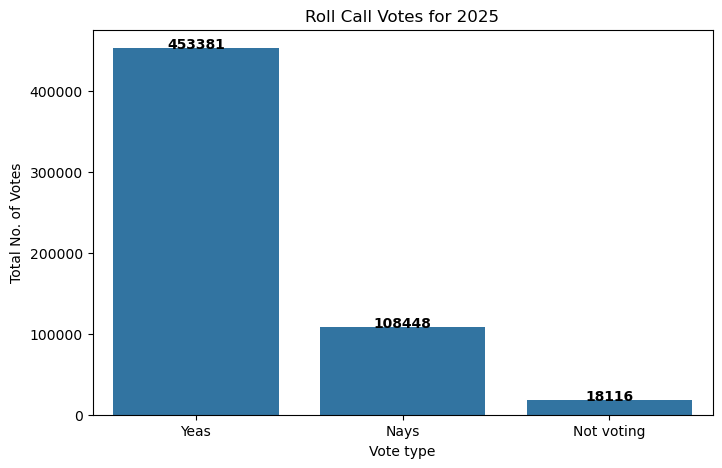

In [169]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
#This code displays a visualization for the 2025 year to date roll call data 
df = pd.read_csv("rollcalls_all_years.csv")
#cover all vote cases
vote_map = {"Y": "Yeas", "N": "Nays", "X": "Not voting"}
df["Vote Type"] = df["Vote"].map(vote_map)

# Count the number of votes per type
vote_counts = df["Vote Type"].value_counts().reindex(["Yeas","Nays","Not voting"], fill_value=0)

# Bar chart
plt.figure(figsize=(8,5))
sns.barplot(x=vote_counts.index, y=vote_counts.values)
plt.title("Roll Call Votes for 2025")
plt.ylabel("Total No. of Votes")
plt.xlabel("Vote type")
for i, v in enumerate(vote_counts.values):
    plt.text(i, v + 1, str(v), ha='center', fontweight='bold')
plt.show()


In [173]:
#plot votes by bill and amendment numbers
def plot_votes(df, bill_no, amendment_no):
    subset = show_amendment_votes(df, bill_no, amendment_no)
    if subset is not None:
        subset["Vote"].value_counts().plot(kind='bar')
        plt.title(f"Votes for {bill_no} {amendment_no}")
        plt.xlabel("Vote")
        plt.ylabel("Count")
        plt.show()

Roll call data for Bill H. 57, Amendment #6

Vote
N    126
Y     26
X      7
Name: count, dtype: int64

Total legislators parsed: 159



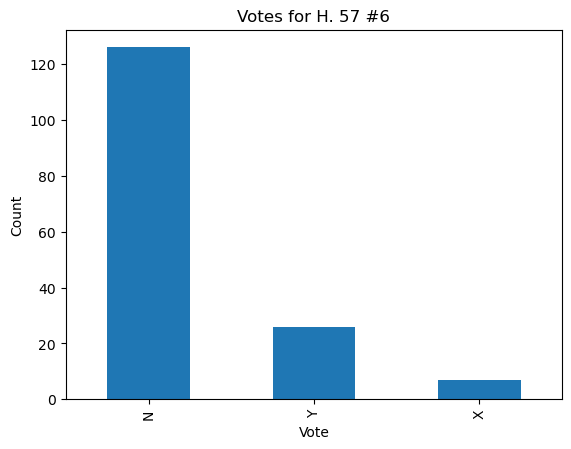

In [175]:
#plotting data for H 57 amendment 6
plot_votes(df, "H. 57", "#6")

In [181]:
def visualize_legislator_summary(df, legislator_name):

    subset = df[df["Legislator Name"].str.contains(legislator_name, case=False, na=False)]

    if subset.empty:
        print(f"No votes found for '{legislator_name}'.")
        return
    vote_counts = subset["Vote"].value_counts()
    plt.figure(figsize=(6,4))
    vote_counts.plot(kind="bar")
    plt.title(f"Voting patterns for {legislator_name} (updated for all sessions)")
    plt.xlabel("Vote type")
    plt.ylabel("Vote Count")
    plt.xticks(rotation=0)
    plt.show()


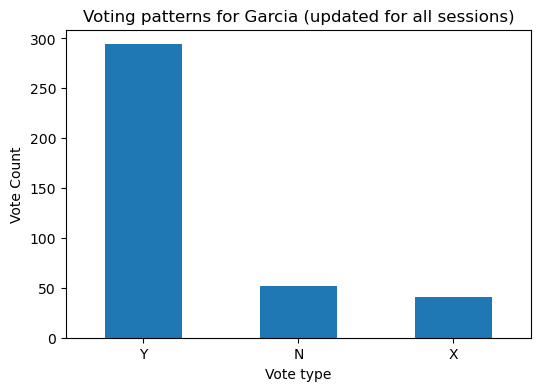

In [183]:
visualize_legislator_summary(df, "Garcia")

In [ ]:
import requests
# pulling data for specific bill from Open States API, could be useful for integrating to the dashboard
API_KEY = "b70ea1c9-daf6-4f4a-83e0-59504cd0a080"
BASE_URL = "https://v3.openstates.org/bills"
bill_id = "H 57"  
jurisdiction = "Massachusetts"

headers = {"X-API-KEY": API_KEY}

params = {
    "jurisdiction": jurisdiction,
    "identifier": bill_id
}

response = requests.get(BASE_URL, params=params, headers=headers)
if response.status_code == 200:
    data = response.json()
    results = data.get("results", [])
    if results:
        bill = results[0]  # assuming identifier is unique
        print("Bill ID:", bill.get("identifier"))
        print("Chamber:", bill.get("from_organization", {}).get("name"))
        print("Title:", bill.get("title"))
        print("First Action:", bill.get("first_action_date"))
        print("Latest Action:", bill.get("latest_action_date"))
        print("Latest Description:", bill.get("latest_action_description"))
        print("Session:", bill.get("session"))
        print("Bill URL:", bill.get("openstates_url"))
    else:
        print("Bill not found")
else:
    print("Error:", response.status_code)